# GalaxyMNIST | A small machine-learning demonstration
**Computational Astrophysics · Physics of Data**

This is a **teaching example**, not a complete morphology-classification pipeline. We will inspect real 64×64 RGB galaxy images, extract a few very simple features, and fit **one** classifier to distinguish **two** categories. The focus is on understanding what the library calls do, how arrays are shaped, and what a confusion matrix means.

The notebook deliberately does **not** perform parameter searches, compare candidate classifiers, evaluate a final model on the official test partition, save reports, or package a command-line tool.

The optional toy data below are **artificial patterns, not galaxy observations**. They are only useful when experimenting offline. Scientific results require genuine GalaxyMNIST images.


## Dependencies and configuration

Install packages into the environment you use for Jupyter:

```bash
python -m pip install numpy matplotlib scikit-learn h5py
```

For the real dataset, follow the [GalaxyMNIST repository](https://github.com/mwalmsley/galaxy_mnist) for download instructions. The HDF5 reader below accepts a file at `data/GalaxyMNIST/raw/train_dataset.hdf5`. If it cannot find that file it attempts to load/download the dataset using the official Python package; to enable this route, install GalaxyMNIST and its PyTorch/torchvision dependencies as described in its README.

The notebook illustrates only two classes: **smooth round** (label 0) and **edge-on disk** (label 2). The full GalaxyMNIST dataset contains four classes.


In [7]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import h5py

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# By default the notebook uses real GalaxyMNIST observations.
# Set True only to demonstrate the programming steps without downloaded data.
USE_TOY_DATA = False
DATA_ROOT = Path("data")
SEED = 42
EXAMPLE_LABELS = (0, 2)
CLASS_NAMES = {0: "smooth_round", 2: "edge_on_disk"}
MAX_PER_CLASS = 120  # keep the in-class example lightweight
rng = np.random.default_rng(SEED)


## Step 1 — Read image arrays

The dataset stores RGB images as `(N, height, width, channels)` and labels as integers. We use only the **training** portion for this educational illustration and construct a small validation subset from it.

Try inspecting `images.shape`, `images.dtype`, and `np.unique(labels)` before moving on. A pixel is an intensity measurement, not a physically calibrated flux in this example.


In [8]:
def make_toy_images(n_per_class=100, seed=42):
    """Artificial test patterns for offline code execution; NOT galaxies."""
    generator = np.random.default_rng(seed)
    yy, xx = np.mgrid[-1:1:64j, -1:1:64j]
    patterns, labels = [], []
    for label in EXAMPLE_LABELS:
        for _ in range(n_per_class):
            size = generator.uniform(0.20, 0.40)
            if label == 0:
                blob = np.exp(-0.5 * (xx**2 + yy**2) / size**2)
            else:
                blob = np.exp(-0.5 * ((xx / (size * 1.8))**2 + (yy / (size * 0.33))**2))
            rgb = np.stack([0.8 * blob, 0.6 * blob, 0.9 * blob], axis=-1)
            rgb += generator.normal(0, 0.035, size=rgb.shape)
            patterns.append((np.clip(rgb, 0, 1) * 255).astype(np.uint8))
            labels.append(label)
    return np.stack(patterns), np.array(labels, dtype=int)


def load_training_images():
    if USE_TOY_DATA:
        print("TOY MODE — these images are synthetic shapes, NOT galaxies")
        return make_toy_images(seed=SEED)

    path = Path("data/GalaxyMNIST/raw/train_dataset.hdf5")
    if path.is_file():
        with h5py.File(path, "r") as handle:
            return handle["images"][:], handle["labels"][:].astype(int)

    try:
        from galaxy_mnist import GalaxyMNIST
        dataset = GalaxyMNIST(root=str(DATA_ROOT), train=True, download=True)
        # This official loader returns image tensors in NCHW order.
        return dataset.data.permute(0, 2, 3, 1).numpy(), dataset.targets.numpy()
    except Exception as exc:
        raise RuntimeError(
            "GalaxyMNIST data are unavailable. See the setup cell: download the official "
            "training HDF5 file or install the GalaxyMNIST package. For a simple offline "
            "programming demonstration only, set USE_TOY_DATA=True."
        ) from exc


images, labels = load_training_images()
assert images.ndim == 4 and images.shape[-1] == 3
assert len(images) == len(labels)
print("Image array:", images.shape, images.dtype)
print("Available labels:", np.unique(labels))

# Restrict to a balanced, deterministic teaching subset (not the full 4-class problem).
chosen = []
for lab in EXAMPLE_LABELS:
    locations = np.flatnonzero(labels == lab)
    if not len(locations):
        raise ValueError(f"No images found for label {lab}")
    chosen.extend(rng.choice(locations, size=min(MAX_PER_CLASS, len(locations)), replace=False))
chosen = np.array(chosen)
images, labels = images[chosen], labels[chosen]
print("Small example subset:", images.shape)


Image array: (8000, 64, 64, 3) uint8
Available labels: [0 1 2 3]
Small example subset: (240, 64, 64, 3)


## Step 2 — Look at actual inputs

Show one labelled image for each demonstration category. Notice that these are **RGB arrays** with values from 0 to 255. This picture is for visual orientation, not a prediction.


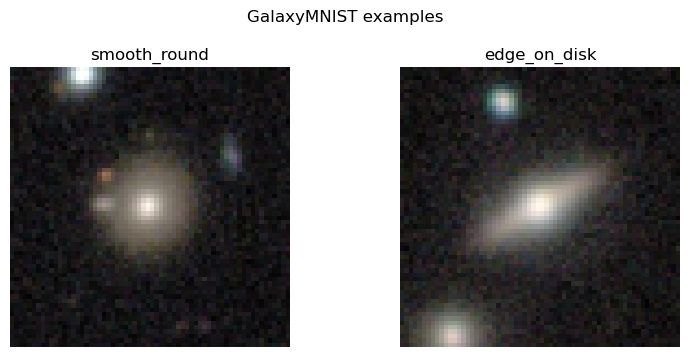

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.6))
for ax, label in zip(axes, EXAMPLE_LABELS):
    sample_idx = int(np.flatnonzero(labels == label)[0])
    ax.imshow(images[sample_idx])
    ax.set_title(CLASS_NAMES[label])
    ax.axis("off")
fig.suptitle("Artificial patterns (not galaxies)" if USE_TOY_DATA else "GalaxyMNIST examples")
fig.tight_layout()
plt.show()


## Step 3 — Translate an image into a small feature vector

A scikit-learn classifier accepts one row of **numbers per object**. For demonstration we retain only a few simple properties: the mean intensity of each RGB channel and the average intensity within a central square. This is intentionally coarse: it discards much of the detailed galaxy morphology.

This is a useful reminder that **feature choice is a modelling decision**. Inspect the matrix shape before fitting anything.


In [10]:
def simple_features(rgb_images):
    # Convert integer pixel values to floating-point intensities in [0, 1].
    a = np.asarray(rgb_images, dtype=np.float32) / 255.0
    global_rgb = a.mean(axis=(1, 2))
    central_rgb = a[:, 24:40, 24:40, :].mean(axis=(1, 2))
    return np.concatenate([global_rgb, central_rgb], axis=1)

X = simple_features(images)
y = labels
print("Feature matrix:", X.shape, "labels:", y.shape)
print("First row:", np.round(X[0], 3))


Feature matrix: (240, 6) labels: (240,)
First row: [0.138 0.13  0.131 0.498 0.463 0.424]


## Step 4 — Separate fitting data from evaluation data

A validation set lets us estimate whether a model works on images it has **not** seen during fitting. Here the validation set comes from the training portion of GalaxyMNIST; the official test set is not used anywhere in this example.


In [11]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)
print("Fitting examples:", X_fit.shape[0], "Validation examples:", X_val.shape[0])


Fitting examples: 180 Validation examples: 60


## Step 5 — Fit one simple classifier

We use *k-nearest neighbours* (kNN) because it provides an intuitive example of the `fit` / `predict` interface. It assigns the category commonly found among nearby training examples in feature space. **This is not a recommended final morphology model**; the point is to see the API and the limitations of simplistic features.


In [12]:
model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_fit, y_fit)
validation_predictions = model.predict(X_val)
print(f"Validation accuracy (illustration only): {accuracy_score(y_val, validation_predictions):.3f}")


Validation accuracy (illustration only): 0.683


## Step 6 — Read a confusion matrix

Rows correspond to **true categories**; columns correspond to **predicted categories**. A single accuracy number may hide which classes are confused. Inspect the off-diagonal entries before drawing conclusions.


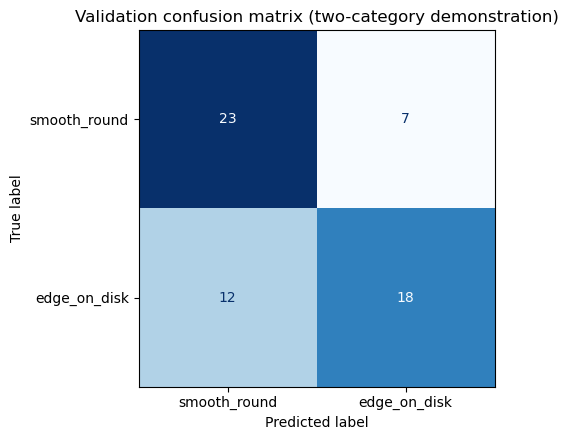

In [13]:
mat = confusion_matrix(y_val, validation_predictions, labels=list(EXAMPLE_LABELS))
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(
    confusion_matrix=mat,
    display_labels=[CLASS_NAMES[i] for i in EXAMPLE_LABELS]
).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Validation confusion matrix (two-category demonstration)")
fig.tight_layout()
plt.show()


## Reflection questions

- How much morphology information is lost when an image becomes only six summary numbers?
- Why is a validation split preferable to measuring accuracy on the very same images used for training?
- What does an off-diagonal entry in the confusion matrix mean?
- What would change if you retained spatial information instead of only channel averages?

**Further reading:** [GalaxyMNIST](https://github.com/mwalmsley/galaxy_mnist) · [scikit-learn supervised learning](https://scikit-learn.org/stable/supervised_learning.html) · [Classification metrics](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics).

This notebook is complete as a *demonstration* but deliberately does not define the larger scientific workflow or generate a report.
